# Iris Flower Classification
**Oasis Infobyte Internship (Data Science) - Task 1**

**Objective:** Train machine learning models that predict the species of an iris flower (Setosa, Versicolor or Virginica) from its sepal and petal measurements.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 70
plt.rcParams['savefig.dpi'] = 70

## 2. Load the Dataset
The Iris dataset ships with scikit-learn, so no download is needed. We convert it into a pandas DataFrame and add a readable species column.

In [2]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Exploratory Data Analysis (EDA)

In [3]:
print('Shape:', df.shape)
print('\nData types:')
print(df.dtypes)
print('\nNull values per column:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())
print('\nClass distribution:')
print(df['species'].value_counts())

Shape: (150, 5)

Data types:
sepal length (cm)     float64
sepal width (cm)      float64
petal length (cm)     float64
petal width (cm)      float64
species              category
dtype: object

Null values per column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Duplicate rows: 1

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [4]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


**Observations:** The dataset has 150 rows and 4 numeric features, with no missing values. Each species has exactly 50 samples, so the classes are perfectly balanced and plain accuracy is a fair metric. (A few duplicate rows exist, but they are genuine measurements, so we keep them.)

## 4. Visualisations

### 4.1 Pairplot (feature distributions by species)

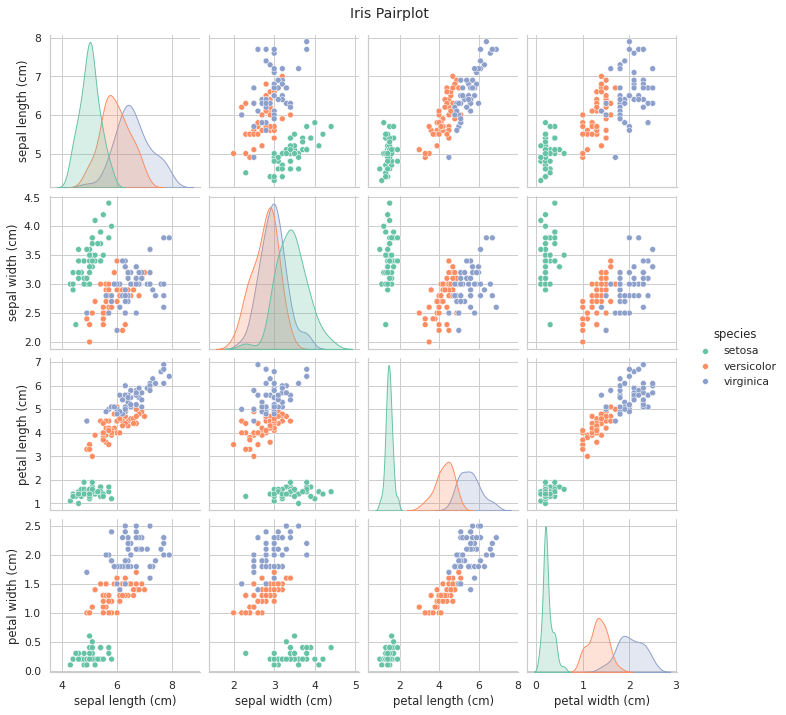

In [5]:
sns.pairplot(df, hue='species', palette='Set2', diag_kind='kde')
plt.suptitle('Iris Pairplot', y=1.02)
plt.show()

**Observation:** Setosa (one colour cluster) is clearly separated from the other two in almost every plot, especially on petal measurements. Versicolor and Virginica overlap a little, which is where a model is most likely to make mistakes.

### 4.2 Box plots for each feature

/tmp/ipykernel_86/2548542542.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='species', y=col, palette='Set2', ax=ax)
/tmp/ipykernel_86/2548542542.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='species', y=col, palette='Set2', ax=ax)
/tmp/ipykernel_86/2548542542.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='species', y=col, palette='Set2', ax=ax)
/tmp/ipykernel_86/2548542542.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign t

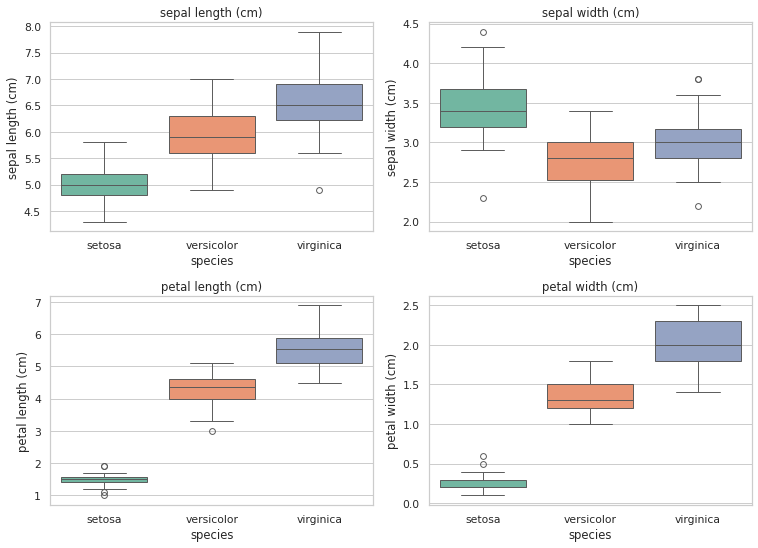

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), iris.feature_names):
    sns.boxplot(data=df, x='species', y=col, palette='Set2', ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 4.3 Correlation heatmap

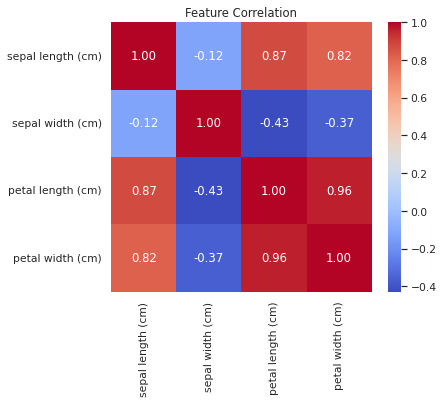

In [7]:
plt.figure(figsize=(6, 5))
sns.heatmap(df.drop(columns='species').corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation')
plt.show()

## 5. Feature Selection Discussion
Which features separate the species best? We check this two ways: the box plots above, and the feature importance from a Random Forest.

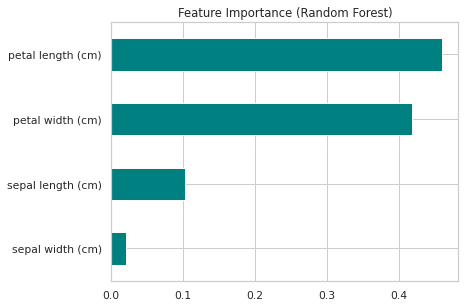

petal length (cm)    0.459290
petal width (cm)     0.417860
sepal length (cm)    0.101969
sepal width (cm)     0.020881
dtype: float64


In [8]:
rf_tmp = RandomForestClassifier(n_estimators=200, random_state=42)
rf_tmp.fit(iris.data, iris.target)
imp = pd.Series(rf_tmp.feature_importances_, index=iris.feature_names).sort_values()
imp.plot(kind='barh', color='teal', title='Feature Importance (Random Forest)')
plt.show()
print(imp.sort_values(ascending=False))

**Conclusion:** Petal length and petal width are the most discriminative features. Their boxes barely overlap across species, while sepal width overlaps heavily and is the weakest feature.

## 6. Train/Test Split (80/20)
We use `stratify=y` so each species appears in the same proportion in both sets.

In [9]:
X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Train size:', X_train.shape[0], '| Test size:', X_test.shape[0])

Train size: 120 | Test size: 30


## 7. Train the Models
We train four classifiers: Logistic Regression, K-Nearest Neighbours, Decision Tree and Random Forest.

In [10]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=200),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    results[name] = model.predict(X_test)

## 8. Evaluate the Models
For each model we show accuracy, the confusion matrix and the classification report (precision, recall, F1).

Logistic Regression  |  Accuracy: 0.9667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

KNN (k=5)  |  Accuracy: 1.0000
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Decision Tree  |  Accuracy: 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.9

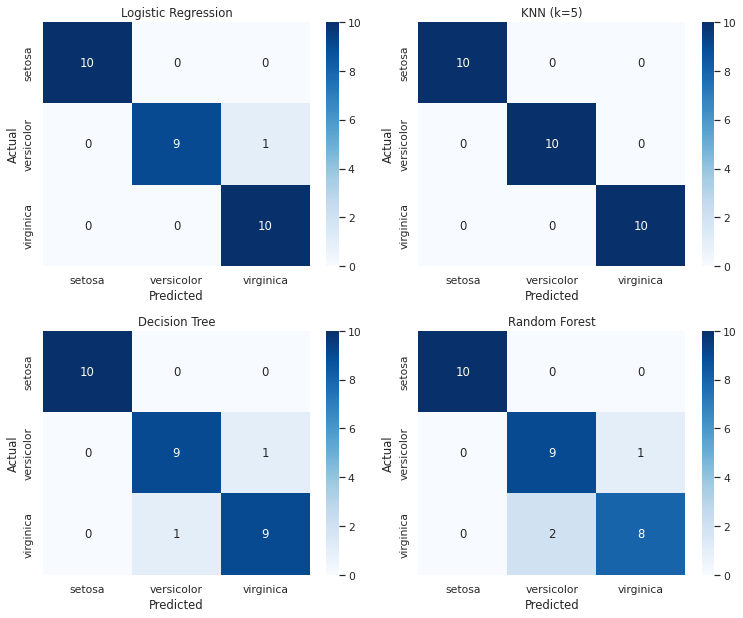

In [11]:
accuracies = {}
for name, y_pred in results.items():
    acc = accuracy_score(y_test, y_pred)
    accuracies[name] = acc
    print('=' * 55)
    print(f'{name}  |  Accuracy: {acc:.4f}')
    print('=' * 55)
    print(classification_report(y_test, y_pred, target_names=iris.target_names))

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, y_pred) in zip(axes.ravel(), results.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=iris.target_names, yticklabels=iris.target_names)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

## 9. Model Comparison

KNN (k=5)              1.000000
Logistic Regression    0.966667
Decision Tree          0.933333
Random Forest          0.900000
dtype: float64


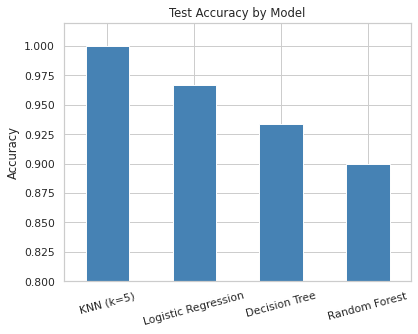

In [12]:
comparison = pd.Series(accuracies).sort_values(ascending=False)
print(comparison)
comparison.plot(kind='bar', color='steelblue', ylim=(0.8, 1.02), rot=15,
                title='Test Accuracy by Model')
plt.ylabel('Accuracy')
plt.show()

## 10. Best Model and Justification
Fill this in after you look at your own output. Suggested points:

- Which model has the highest test accuracy, and by how much?
- Which species pair does it confuse (usually Versicolor vs Virginica)?
- The test set has only 30 samples, so one mistake changes accuracy by about 3%. Differences between top models may be down to chance, so a simpler model such as Logistic Regression or KNN can be a perfectly good choice.

**Conclusion:** (write your final declaration here)

## 11. Predict a New Flower (Demo)

In [13]:
best_name = comparison.index[0]
best_model = models[best_name]
sample = pd.DataFrame([[5.1, 3.5, 1.4, 0.2]], columns=iris.feature_names)
pred = best_model.predict(sample)[0]
print(f'Best model: {best_name}')
print('Predicted species for [5.1, 3.5, 1.4, 0.2]:', iris.target_names[pred])

Best model: KNN (k=5)
Predicted species for [5.1, 3.5, 1.4, 0.2]: setosa


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(
